<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">03 · Computer Vision basics: Fashion-MNIST</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">An image is a grid of numbers: how does a model read it?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/02_computer_vision/01_mini_project_fashion_mnist/03_Computer_Vision_Basics_Fashion_MNIST.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#fashion)

## 🎯 Objectives
By the end of this notebook you will be able to:

- explain why, for a computer, **an image is just a grid of numbers** (pixels);
- **flatten** an image into one long row and train the **MLP** you built in Lesson 02 on it;
- apply a **convolution by hand** (an edge detector) and say what a *kernel* and a *feature map* are;
- train a small **CNN** in PyTorch and show that it beats the MLP with **far fewer parameters**;
- read a 10-class **confusion matrix** and a gallery of the model's most confident mistakes.

**⏱️ Duration:** ≈ 60 min · **📋 Prerequisites:** Lesson 02 (MLP, PyTorch training loop, confusion matrix, overfitting) · **▶️ How to use:** run the cells in order with `Shift`+`Enter`; try the ✏️ exercises before opening the solutions. The whole notebook runs in 1–2 minutes on a laptop CPU.

## 📑 Contents

1. [👗 Meet Fashion-MNIST](#sec-1)
2. [🔢 A computer sees numbers](#sec-2)
3. [🧮 Flatten it: the MLP from Lesson 02](#sec-3)
4. [🔍 Convolution by hand](#sec-4)
5. [🧱 A small CNN](#sec-5)
6. [📏 Evaluation: where does it fail?](#sec-6)
7. [✏️ Exercises](#sec-7)
8. [📌 Summary](#sec-8)
9. [📚 Learn more](#sec-9)

<a id="sec-0"></a>
## ⚙️ Setup

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    os.chdir(ROOT)  # Colab already has torch, torchvision, matplotlib and ipywidgets: nothing to install
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

sys.path.insert(0, str(ROOT))
print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from src.paths import cache_dir, models_dir
from src.plotting import PALETTE, apply_style, label_bars, plot_confusion, plot_history
from src.vision import (FASHION_CLASSES, KERNELS, apply_kernel, count_parameters, evaluate,
                        load_fashion_mnist, save_slide_image, set_seed, show_grid, train_model)

apply_style()
SEED = 42
set_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
T_START = time.perf_counter()

# Only the authors use this (EXPORT_SLIDES=1) to refresh the images in the slide deck.
EXPORT_SLIDES = os.environ.get("EXPORT_SLIDES") == "1"
def save_slide(fig, name):
    if EXPORT_SLIDES:
        save_slide_image(fig, ROOT / "assets" / "slides" / name)

print("PyTorch", torch.__version__, "| device: CPU (this notebook does not need a GPU)")

PyTorch 2.15.0+cpu | device: CPU (this notebook does not need a GPU)


> 💡 **Tip:** in Colab there is nothing to install. Locally, run `uv sync` at the project root and pick the `.venv` kernel. The first run downloads Fashion-MNIST (≈ 30 MB) into `data/_cache/`.

### 📖 Words you will meet (mini-glossary)

| Term | In plain words |
|---|---|
| **pixel** | one dot of the image; here a number from 0 (black) to 255 (white) |
| **grayscale / RGB** | one number per pixel (grey) or three numbers per pixel (red, green, blue) — the **channels** |
| **resolution** | how many pixels: Fashion-MNIST images are 28 × 28 = 784 pixels |
| **flatten** | put the rows of the image one after the other, making one long list of numbers |
| **kernel (filter)** | a tiny grid of weights (e.g. 3 × 3) that slides over the image looking for one pattern |
| **convolution** | sliding the kernel over the image and, at each position, multiplying and summing |
| **feature map** | the new "image" produced by one kernel: bright where the pattern was found |
| **pooling** | shrinking a feature map by keeping the largest value of each 2 × 2 block |
| **CNN** | *convolutional neural network*: layers of kernels that are **learned**, not hand-made |
| **logits / softmax** | the raw scores of the 10 classes / the same scores turned into probabilities that add up to 1 |

<a id="sec-1"></a>
# 1. 👗 Meet Fashion-MNIST

**Fashion-MNIST** (Zalando Research, 2017) has 70,000 small grayscale photos of clothes from an online shop: 60,000 to train and 10,000 to test, 10 classes, perfectly balanced. It was created as a harder drop-in replacement for the famous MNIST handwritten digits. `torchvision` downloads it for us.

In [3]:
X_train_u8, y_train = load_fashion_mnist(cache_dir(), train=True)    # uint8 images, int64 labels
X_test_u8, y_test = load_fashion_mnist(cache_dir(), train=False)
print("train:", tuple(X_train_u8.shape), X_train_u8.dtype, "| test:", tuple(X_test_u8.shape))
print("pixel values from", X_train_u8.min().item(), "to", X_train_u8.max().item())
counts = pd.Series(y_train.numpy()).value_counts().sort_index()
pd.DataFrame({"class": FASHION_CLASSES, "train images": counts.values}).T

train: (60000, 28, 28) torch.uint8 | test: (10000, 28, 28)
pixel values from 0 to 255


,0,1,2,3,4,5,6,7,8,9
class,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
train images,6000,6000,6000,6000,6000,6000,6000,6000,6000,6000


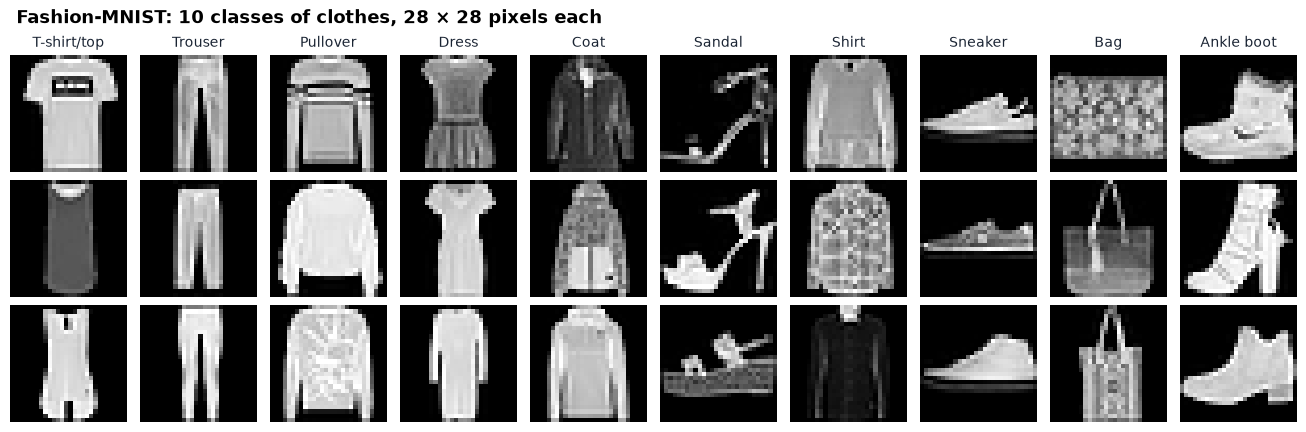

In [4]:
# Three examples of each class (columns = classes)
idx = [np.flatnonzero(y_train.numpy() == c)[k] for k in range(3) for c in range(10)]
titles = [FASHION_CLASSES[y_train[j]] if k < 10 else "" for k, j in enumerate(idx)]   # names on the first row
fig = show_grid([X_train_u8[j] for j in idx], titles=titles, ncols=10, size=1.3, cmap="gray",
                suptitle="Fashion-MNIST: 10 classes of clothes, 28 × 28 pixels each")
plt.show()

Some classes look alike even to us: **Shirt**, **T-shirt/top**, **Pullover** and **Coat** are all "something with sleeves". Keep that in mind: it is where the models will make most of their mistakes.

<a id="sec-2"></a>
# 2. 🔢 A computer sees numbers

## 🧠 How it works: an image is a table

**Simple idea.** You see an ankle boot. The computer sees a **table of 28 rows × 28 columns**, and in each cell a number: 0 = black, 255 = white. That is all. There is no "boot" in the file, only 784 numbers.

**Steps:** (1) the camera measures the light in each tiny square; (2) each measurement becomes a number; (3) a colour photo stores **three** tables (red, green, blue); (4) the model must find "boot-ness" in those numbers.

**Analogy.** A mosaic seen from very close: each tile is just one colour. Step back and you see a picture.

**Limits.** The same boot moved 3 pixels to the right gives a *completely different list of numbers* — even though for us it is the same boot. Remember this: it is the reason convolutions were invented.

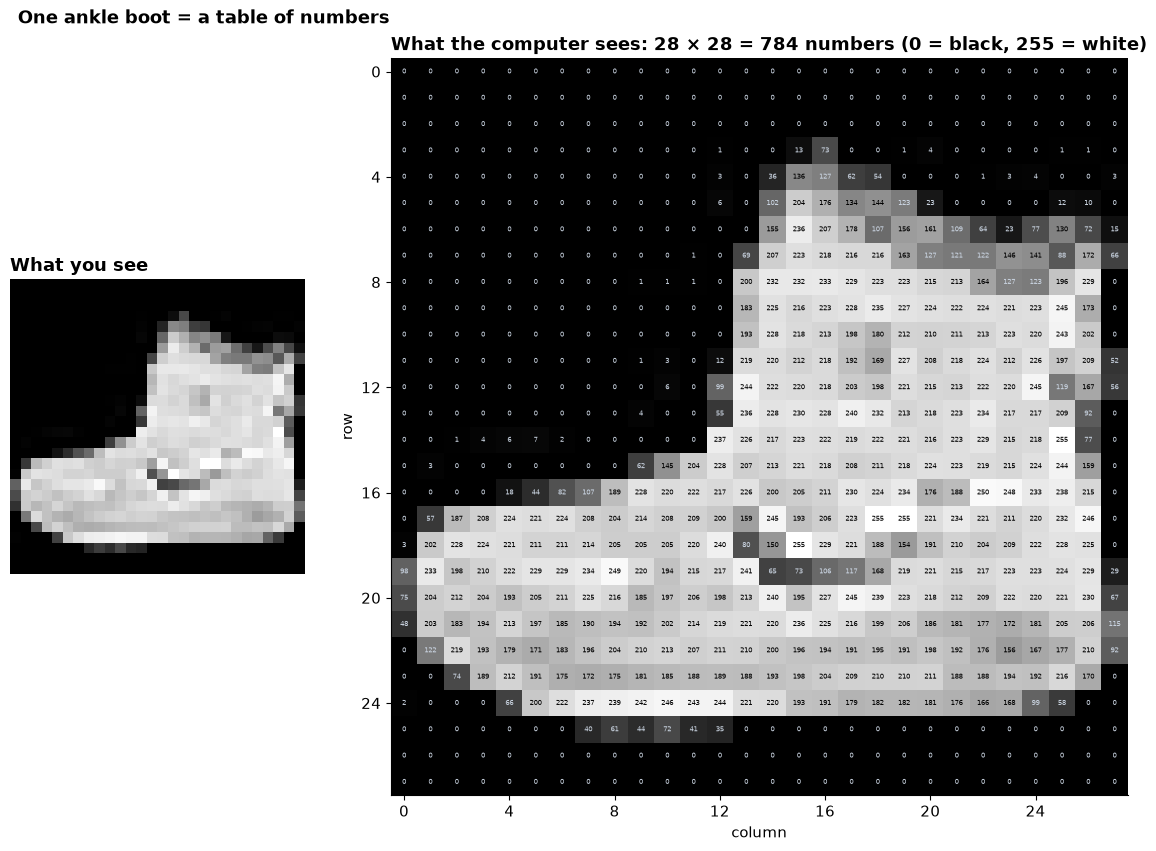

the same image as an array: (28, 28) uint8 | first non-black row: 3


In [5]:
i = int(np.flatnonzero(y_train.numpy() == 9)[0])        # the first ankle boot
img = X_train_u8[i].numpy()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 8.4), width_ratios=[1, 3], layout="constrained")
ax0.imshow(img, cmap="gray"); ax0.set_title("What you see"); ax0.axis("off")
ax1.imshow(img, cmap="gray", vmin=0, vmax=255)
for r in range(28):
    for c in range(28):
        v = int(img[r, c])
        ax1.text(c, r, str(v), ha="center", va="center", fontsize=5.2,
                 color="black" if v > 128 else "#c9d3e0")
ax1.set_xticks(range(0, 28, 4)); ax1.set_yticks(range(0, 28, 4)); ax1.grid(False)
ax1.set(xlabel="column", ylabel="row", title="What the computer sees: 28 × 28 = 784 numbers (0 = black, 255 = white)")
fig.suptitle(f"One {FASHION_CLASSES[y_train[i]].lower()} = a table of numbers", x=0.01, ha="left", fontweight="bold")
save_slide(fig, "cv-pixel-numbers.png")
plt.show()
print("the same image as an array:", img.shape, img.dtype, "| first non-black row:", int(np.argmax(img.max(1) > 0)))

### 💬 Discussion — Is the computer "seeing"?

Look at the table of numbers without the picture on the left. Could you tell it is a boot? What would change in the numbers if the boot were **darker**, **smaller** or **moved to the left**?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

With the numbers only, you can still spot the shape because bright numbers cluster where the boot is — but it is slow and you rely on *neighbours*: a bright cell surrounded by bright cells. That is exactly what a convolution exploits later. Darker → all numbers smaller (models usually rescale to 0–1 to make this easier). Smaller or moved → the bright numbers land in *different* cells: for a model that reads cell 1, cell 2, … cell 784 in a fixed order (the MLP), it is a different input. Ask the class to keep this in mind for section 3.
</details>

<a id="sec-3"></a>
# 3. 🧮 Flatten it: the MLP from Lesson 02

In Lesson 02 the 8 × 8 digits of `load_digits` became rows of **64 numbers** and an MLP learned to classify them. We do exactly the same here, only bigger: each image becomes a row of **784 numbers** (scaled to 0–1), and the MLP has two hidden layers.

```
28 × 28 image  ──flatten──►  [x₁, x₂, …, x₇₈₄]  ──►  256 neurons  ──►  128 neurons  ──►  10 scores (one per class)
```

**Three sets, like in Lesson 02.** We cut **10,000 validation images** out of the 60,000 training images. The **validation** set is used to watch the training and to compare the MLP with the CNN; the official **test** set (10,000 images) stays locked until section 6, where we use it **once** for the final score.

| Set | Images | Used for |
|---|---|---|
| train | 50,000 | learning the weights |
| validation | 10,000 | curves per epoch, comparing models, the shift test |
| test | 10,000 | the final exam, once, at the end |

> ⚠️ **Watch out:** the **evaluation loaders never shuffle**. We compare predictions with labels by position; shuffling only the predictions (or only the labels) is a classic silent bug that makes a good model look random.

In [6]:
X_train = X_train_u8[:, None].float() / 255.0          # (60000, 1, 28, 28), values 0..1
X_test = X_test_u8[:, None].float() / 255.0
perm = torch.randperm(len(X_train), generator=torch.Generator().manual_seed(SEED))
val_idx, tr_idx = perm[:10_000], perm[10_000:]          # random 10,000 for validation, 50,000 to train
X_val_u8, y_val = X_train_u8[val_idx], y_train[val_idx]

train_dl = DataLoader(TensorDataset(X_train[tr_idx], y_train[tr_idx]), batch_size=128, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))
val_dl = DataLoader(TensorDataset(X_train[val_idx], y_val), batch_size=1000, shuffle=False)   # fixed order!
test_dl = DataLoader(TensorDataset(X_test, y_test), batch_size=1000, shuffle=False)          # locked until section 6
print("train:", len(tr_idx), "| validation:", len(val_idx), "| test:", len(X_test),
      "| validation images per class:", np.bincount(y_val.numpy()).min(), "to", np.bincount(y_val.numpy()).max())
EPOCHS = 4

mlp = nn.Sequential(
    nn.Flatten(),                              # (batch, 1, 28, 28) -> (batch, 784)
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 10),                        # 10 logits; CrossEntropyLoss applies the softmax
)
print(f"MLP parameters: {count_parameters(mlp):,}")
set_seed(SEED)
hist_mlp = train_model(mlp, train_dl, val_dl, epochs=EPOCHS, lr=2e-3)
res_mlp = evaluate(mlp, val_dl)
print(f"MLP validation accuracy: {res_mlp['accuracy']:.1%}  (guessing at random: 10%)")

train: 50000 | validation: 10000 | test: 10000 | validation images per class: 957 to 1061
MLP parameters: 235,146


epoch  1/4: train loss 0.546 acc 0.804 | val loss 0.412 acc 0.848 | 1.6 s


epoch  2/4: train loss 0.384 acc 0.861 | val loss 0.390 acc 0.856 | 1.7 s


epoch  3/4: train loss 0.339 acc 0.876 | val loss 0.351 acc 0.872 | 1.4 s


epoch  4/4: train loss 0.314 acc 0.885 | val loss 0.358 acc 0.867 | 1.4 s
MLP validation accuracy: 86.7%  (guessing at random: 10%)


## 🧠 What did the MLP's first layer learn?

Each of the 256 neurons of the first layer has **784 weights, one per pixel**. Put them back into a 28 × 28 grid and you can *see* what the neuron is looking for: **red** pixels push the neuron up, **blue** pixels push it down. Several look like blurry **outlines**: two trouser legs, the sole of a shoe, the shoulders and sleeves of a top. The MLP learned *where* light and dark pixels usually are — at fixed positions.

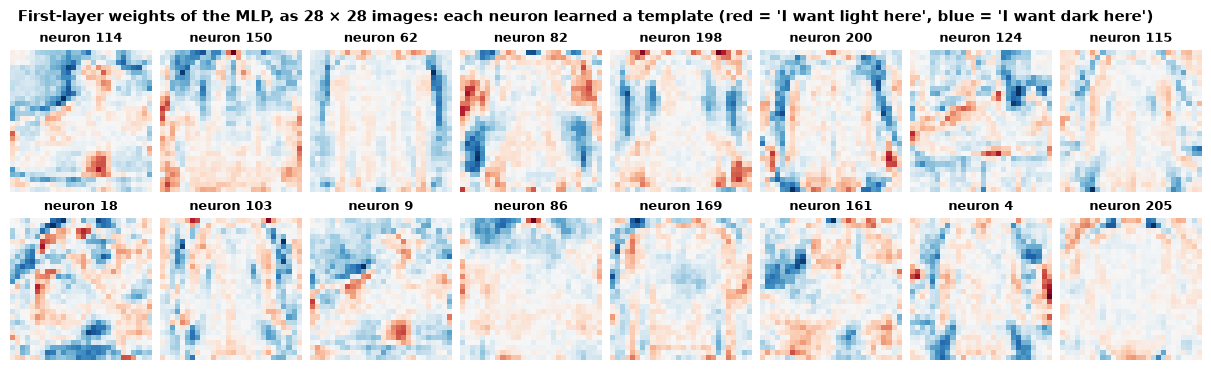

In [7]:
W = mlp[1].weight.detach().numpy()                     # (256, 784)
strongest = np.argsort(-np.abs(W).sum(1))[:16]         # the 16 neurons with the largest weights
fig, axes = plt.subplots(2, 8, figsize=(12, 3.6), layout="constrained")
for ax, k in zip(axes.ravel(), strongest):
    w = W[k].reshape(28, 28); lim = np.abs(w).max()
    ax.imshow(w, cmap="RdBu_r", vmin=-lim, vmax=lim); ax.axis("off"); ax.set_title(f"neuron {k}", fontsize=9, loc="center")
fig.suptitle("First-layer weights of the MLP, as 28 × 28 images: each neuron learned a template "
             "(red = 'I want light here', blue = 'I want dark here')", x=0.01, ha="left", fontsize=11, fontweight="bold")
save_slide(fig, "cv-mlp-weights.png")
plt.show()

### 🧪 The weak spot: move the image 3 pixels

The MLP reads pixel 1, pixel 2, … pixel 784 at **fixed positions**. What happens if we shift every validation image 3 pixels to the right (filling with black)?

In [8]:
def shift_right(x, pixels=3):
    """Move every image `pixels` to the right; the empty columns on the left become black."""
    out = torch.zeros_like(x)
    out[..., pixels:] = x[..., :-pixels]
    return out

shifted_dl = DataLoader(TensorDataset(shift_right(X_train[val_idx]), y_val), batch_size=1000, shuffle=False)
acc_mlp_shift = evaluate(mlp, shifted_dl)["accuracy"]
print(f"MLP accuracy: {res_mlp['accuracy']:.1%} on the validation images -> {acc_mlp_shift:.1%} with the same images moved 3 px")

MLP accuracy: 86.7% on the validation images -> 33.3% with the same images moved 3 px


Same clothes, same model, a much lower score: for the MLP a moved boot is a new pattern it never saw. We need a model that looks for **local patterns anywhere in the image**. That is what a convolution does.

<a id="sec-4"></a>
# 4. 🔍 Convolution by hand

## 🧠 How it works: the sliding magnifying glass

**Simple idea.** Take a tiny grid of 3 × 3 weights — the **kernel**. Put it on the top-left corner of the image, multiply each of the 9 pixels under it by the weight on top of it, add the 9 results: that is **one number** of the output. Slide one pixel to the right and repeat. The result is a new image, the **feature map**.

**Steps:** (1) choose a kernel (here, by hand: an *edge detector*); (2) slide it over every position; (3) at each position: multiply and sum; (4) bright output = "the pattern is here".

**Analogy.** A magnifying glass that only lights up when it is on top of a vertical edge. Move it across the whole picture and you get a map of where the edges are.

**Why it fixes the MLP's weak spot.** The **same 9 weights** are used at every position. A boot edge on the left or on the right lights up the same way — just in a different place of the map.

**Limits.** One kernel finds one simple pattern. A CNN learns **many** kernels, and stacks layers so later kernels combine edges into shapes (a sole, a heel, a collar).

In [9]:
kernel = KERNELS["vertical edges"]                 # Sobel filter: left side negative, right side positive
img01 = X_train[i, 0].numpy()                      # our ankle boot, values 0..1
r, c = 14, 8                                       # one position in the image
patch = img01[r - 1:r + 2, c - 1:c + 2]
by_hand = (patch * kernel).sum()                   # multiply pixel by weight, then add the 9 numbers
fmap = apply_kernel(img01, kernel)                 # the same operation at every position (PyTorch conv2d)

print("3 × 3 patch of pixels around (row 14, col 8):\n", patch.round(2))
print("kernel (vertical edge detector):\n", kernel.astype(int))
print(f"multiply + sum by hand = {by_hand:.3f} | conv2d at the same position = {fmap[r, c]:.3f}")

3 × 3 patch of pixels around (row 14, col 8):
 [[0.   0.   0.02]
 [0.   0.   0.  ]
 [0.   0.   0.24]]
kernel (vertical edge detector):
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]
multiply + sum by hand = 0.259 | conv2d at the same position = 0.259


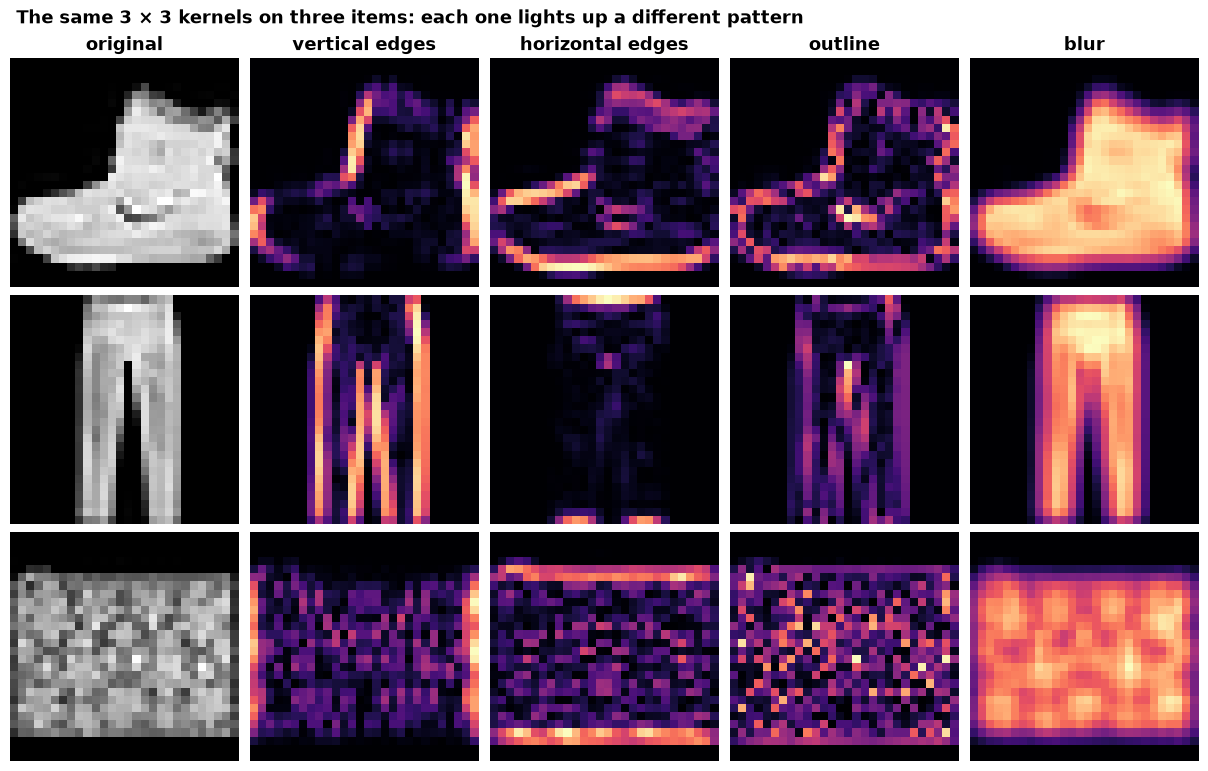

In [10]:
names = ["vertical edges", "horizontal edges", "outline", "blur"]
samples = [i, int(np.flatnonzero(y_train.numpy() == 1)[0]), int(np.flatnonzero(y_train.numpy() == 8)[0])]
fig, axes = plt.subplots(len(samples), 1 + len(names), figsize=(12, 7.6), layout="constrained")
for row, j in enumerate(samples):
    x = X_train[j, 0].numpy()
    axes[row, 0].imshow(x, cmap="gray"); axes[row, 0].set_title("original" if row == 0 else "", loc="center")
    for col, name in enumerate(names, start=1):
        out = apply_kernel(x, KERNELS[name])
        axes[row, col].imshow(np.abs(out) if "edges" in name or name == "outline" else out, cmap="magma")
        if row == 0:
            axes[row, col].set_title(name, loc="center")
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("The same 3 × 3 kernels on three items: each one lights up a different pattern", x=0.01, ha="left", fontweight="bold")
plt.show()

## 🧠 How it works: pooling (shrink, keep the strongest)

After a convolution, a **max-pooling** layer keeps only the largest value of each 2 × 2 block: the map becomes 4× smaller, keeps the "the pattern is here" signal and forgets a little *exactly where*. That makes the next layer cheaper and a bit more tolerant to small shifts.

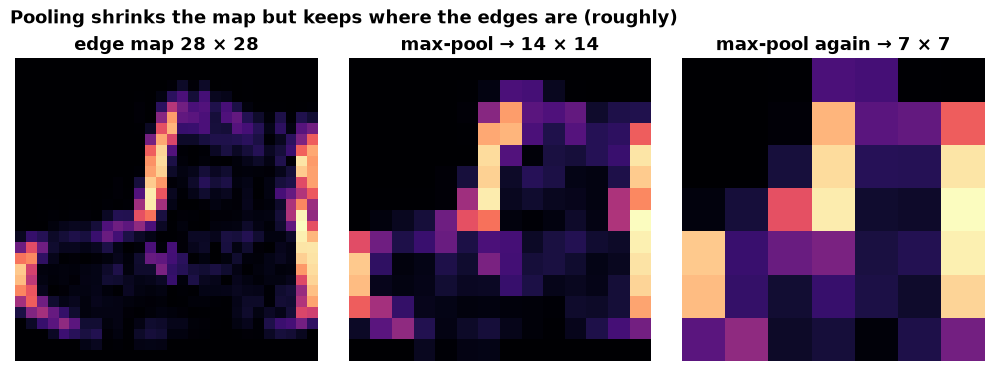

In [11]:
edges = np.abs(apply_kernel(img01, KERNELS["vertical edges"]))
pooled = nn.functional.max_pool2d(torch.tensor(edges)[None, None], 2)[0, 0].numpy()
pooled2 = nn.functional.max_pool2d(torch.tensor(pooled)[None, None], 2)[0, 0].numpy()
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), layout="constrained")
for ax, m, t in zip(axes, (edges, pooled, pooled2), ("edge map 28 × 28", "max-pool → 14 × 14", "max-pool again → 7 × 7")):
    ax.imshow(m, cmap="magma"); ax.set_title(t, loc="center"); ax.axis("off")
fig.suptitle("Pooling shrinks the map but keeps where the edges are (roughly)", x=0.01, ha="left", fontweight="bold")
plt.show()

### 💬 Discussion — Who designs the kernels?

We wrote the edge detector by hand. Before 2012, computer vision engineers did exactly that: they designed filters for edges, corners, textures… What is the problem with that approach, and what does a CNN do differently?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Hand-made filters only find what the engineer thought of, and they break when the lighting, the angle or the object changes. A CNN starts with **random** kernels and **learns** their 9 weights with backprop, the same way the MLP learned its weights in Lesson 02. The first layer usually ends up with edge and colour detectors (like ours!), deeper layers with textures and parts. AlexNet (2012) showed that learned filters beat years of hand-made ones on ImageNet.
</details>

<a id="sec-5"></a>
# 5. 🧱 A small CNN

Two convolution blocks (16 and 32 kernels of 3 × 3, each followed by ReLU and max-pooling), then a single linear layer that reads the final 32 maps of 7 × 7:

```
1×28×28 ─conv 16─► 16×28×28 ─pool─► 16×14×14 ─conv 32─► 32×14×14 ─pool─► 32×7×7 ─flatten─► 1568 ─linear─► 10
```

The kernels start random and are **learned**. Same optimiser (AdamW), same loss, same epochs as the MLP: only the architecture changes.

In [12]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 16 learned kernels
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 kernels over 16 maps
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.2), nn.Linear(32 * 7 * 7, 10))

    def forward(self, x):
        return self.head(self.features(x))

set_seed(SEED)
cnn = FashionCNN()
print(f"CNN parameters: {count_parameters(cnn):,}  vs  MLP: {count_parameters(mlp):,}")
hist_cnn = train_model(cnn, train_dl, val_dl, epochs=EPOCHS, lr=2e-3)
res_cnn = evaluate(cnn, val_dl)
acc_cnn_shift = evaluate(cnn, shifted_dl)["accuracy"]
torch.save(cnn.state_dict(), models_dir() / "fashion_cnn.pt")
print(f"CNN validation accuracy: {res_cnn['accuracy']:.1%} | with images moved 3 px: {acc_cnn_shift:.1%}")

CNN parameters: 20,490  vs  MLP: 235,146


epoch  1/4: train loss 0.563 acc 0.796 | val loss 0.396 acc 0.857 | 7.5 s


epoch  2/4: train loss 0.369 acc 0.868 | val loss 0.349 acc 0.877 | 7.2 s


epoch  3/4: train loss 0.329 acc 0.883 | val loss 0.323 acc 0.884 | 6.8 s


epoch  4/4: train loss 0.310 acc 0.889 | val loss 0.289 acc 0.897 | 7.4 s


CNN validation accuracy: 89.7% | with images moved 3 px: 53.6%


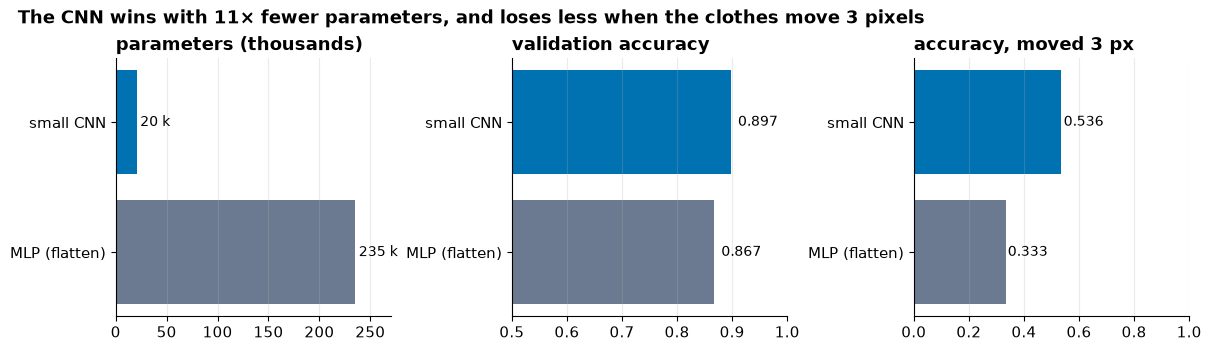

,parameters,validation accuracy,"accuracy, moved 3 px",training time (s)
MLP (flatten),"235,146",86.7%,33.3%,6
small CNN,"20,490",89.7%,53.6%,29


In [13]:
board = pd.DataFrame({
    "parameters": [count_parameters(mlp), count_parameters(cnn)],
    "validation accuracy": [res_mlp["accuracy"], res_cnn["accuracy"]],
    "accuracy, moved 3 px": [acc_mlp_shift, acc_cnn_shift],
    "training time (s)": [sum(hist_mlp["seconds"]), sum(hist_cnn["seconds"])],
}, index=["MLP (flatten)", "small CNN"])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), layout="constrained")
colours = [PALETTE["grey"], PALETTE["blue"]]
for ax, col, fmt in zip(axes, ("parameters", "validation accuracy", "accuracy, moved 3 px"), (0, 3, 3)):
    vals = board[col].values / (1000 if col == "parameters" else 1)
    ax.barh(range(2), vals, color=colours); ax.set_yticks(range(2), board.index)
    label_bars(ax, vals, decimals=0 if col == "parameters" else 3, suffix=" k" if col == "parameters" else "")
    ax.set_title(col if col != "parameters" else "parameters (thousands)", loc="left"); ax.grid(axis="y", visible=False)
axes[1].set_xlim(0.5, 1.0); axes[2].set_xlim(0, 1.0)
fig.suptitle(f"The CNN wins with {count_parameters(mlp) / count_parameters(cnn):.0f}× fewer parameters, "
             "and loses less when the clothes move 3 pixels", x=0.01, ha="left", fontweight="bold")
save_slide(fig, "cv-mlp-vs-cnn.png")
plt.show()
display(board.style.format({"parameters": "{:,}", "validation accuracy": "{:.1%}", "accuracy, moved 3 px": "{:.1%}",
                            "training time (s)": "{:.0f}"}))

The CNN is more accurate with about a tenth of the parameters. On moved images it also drops, but **less** than the MLP: its kernels find edges anywhere, and pooling forgives small shifts. It is *more tolerant, not immune* — the last layer still reads the maps at fixed positions. The full fix is to show the model moved images during training (**data augmentation**, exercise 4 and notebook 04).

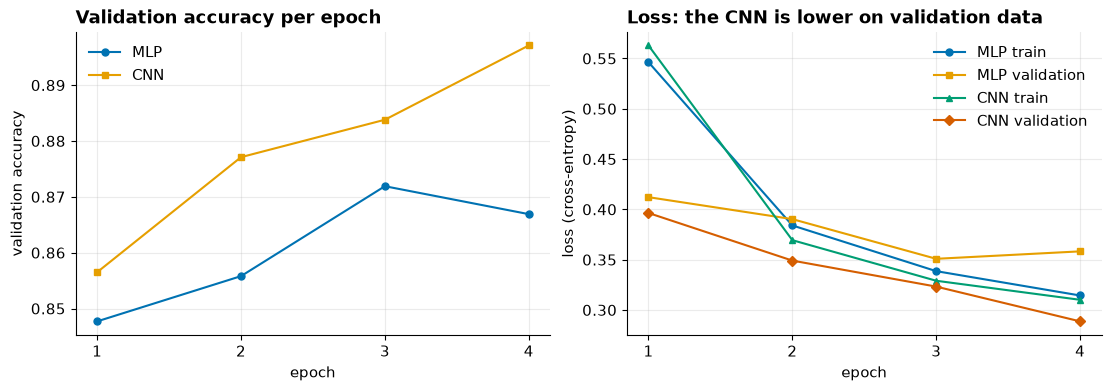

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
plot_history({"MLP": hist_mlp["acc_va"], "CNN": hist_cnn["acc_va"]}, ylabel="validation accuracy",
             title="Validation accuracy per epoch", ax=axes[0])
plot_history({"MLP train": hist_mlp["loss_tr"], "MLP validation": hist_mlp["loss_va"],
              "CNN train": hist_cnn["loss_tr"], "CNN validation": hist_cnn["loss_va"]},
             ylabel="loss (cross-entropy)", title="Loss: the CNN is lower on validation data", ax=axes[1])
for ax in axes: ax.set_xticks(range(1, EPOCHS + 1))
plt.show()

## 🔬 Inside the CNN: learned kernels and feature maps

Which kernels did the first layer learn? And what does our ankle boot look like after it? A **forward hook** (a small function PyTorch calls when a layer runs) lets us grab the 16 feature maps of the first convolution.

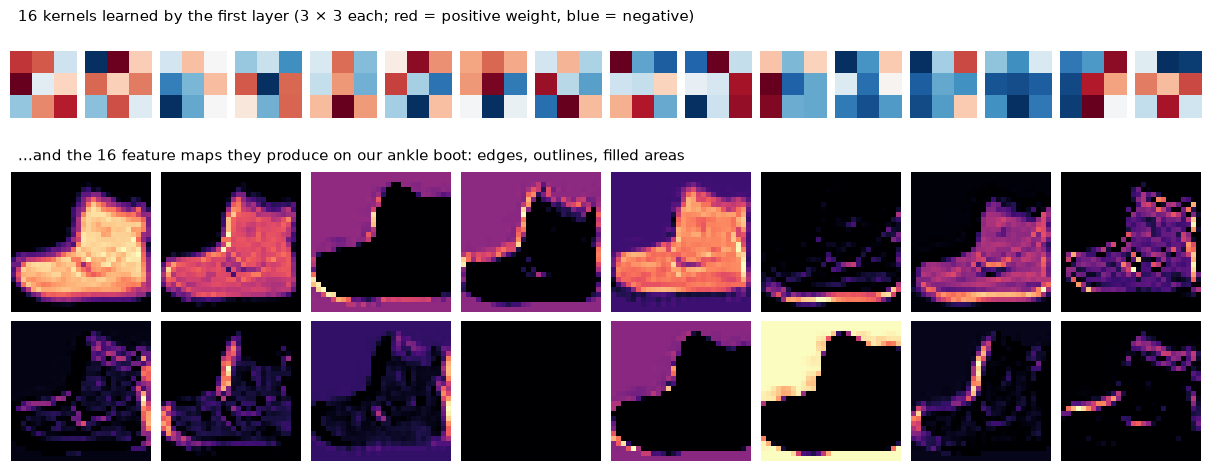

In [15]:
maps = {}
hook = cnn.features[1].register_forward_hook(lambda m, inp, out: maps.update(first=out.detach()))  # after ReLU
cnn.eval()
with torch.no_grad():
    cnn(X_train[i:i + 1])
hook.remove()

kernels = cnn.features[0].weight.detach()[:, 0].numpy()       # (16, 3, 3)
fig = plt.figure(figsize=(12, 4.6), layout="constrained")
top, bottom = fig.subfigures(2, 1, height_ratios=[0.42, 1])
ax_k = top.subplots(1, 16)
for ax, k in zip(ax_k, kernels):
    lim = np.abs(k).max(); ax.imshow(k, cmap="RdBu_r", vmin=-lim, vmax=lim); ax.axis("off")
top.suptitle("16 kernels learned by the first layer (3 × 3 each; red = positive weight, blue = negative)", x=0.01, ha="left", fontsize=11)
ax_m = bottom.subplots(2, 8)
for ax, fm in zip(ax_m.ravel(), maps["first"][0].numpy()):
    ax.imshow(fm, cmap="magma"); ax.axis("off")
bottom.suptitle("…and the 16 feature maps they produce on our ankle boot: edges, outlines, filled areas", x=0.01, ha="left", fontsize=11)
save_slide(fig, "cv-feature-maps.png")
plt.show()

Some kernels look like our hand-made edge detectors (negative on one side, positive on the other), others react to the whole filled shape or to the background. Nobody told the network to look for edges: **it learned that edges are useful** to tell clothes apart.

### 💬 Discussion — Why fewer parameters but better?

The CNN has about 10× fewer parameters than the MLP and is more accurate. How can a *smaller* model be *better*?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Two built-in assumptions ("inductive biases") that are true for images: **(1) locality** — a pixel is mostly related to its neighbours, so a kernel only looks at 3 × 3 pixels instead of all 784; **(2) weight sharing** — the same pattern can appear anywhere, so the same 9 weights are reused at every position. The MLP has to learn a separate weight for "edge at position 100" and "edge at position 101". Fewer parameters also means less room to memorise noise (less overfitting). The shift test shows the second point directly.
</details>

<a id="sec-6"></a>
# 6. 📏 Evaluation: where does it fail?

Validation chose the CNN. Now — **once** — we open the locked **test** set: 10,000 images that played no part in training or in choosing the model. This is the number you would report.

In [16]:
test_mlp = evaluate(mlp, test_dl)
test_cnn = evaluate(cnn, test_dl)
pd.DataFrame({"validation accuracy": [res_mlp["accuracy"], res_cnn["accuracy"]],
              "test accuracy (final)": [test_mlp["accuracy"], test_cnn["accuracy"]]},
             index=["MLP (flatten)", "small CNN"]).style.format("{:.1%}")

,validation accuracy,test accuracy (final)
MLP (flatten),86.7%,86.3%
small CNN,89.7%,88.8%


The test scores are a little lower than the validation ones (by about 0.5–1 point). That is normal: we picked the model that looked best on validation, so validation is slightly optimistic. The gap is small, so validation was an honest stand-in — and the **test** number is the one to report.

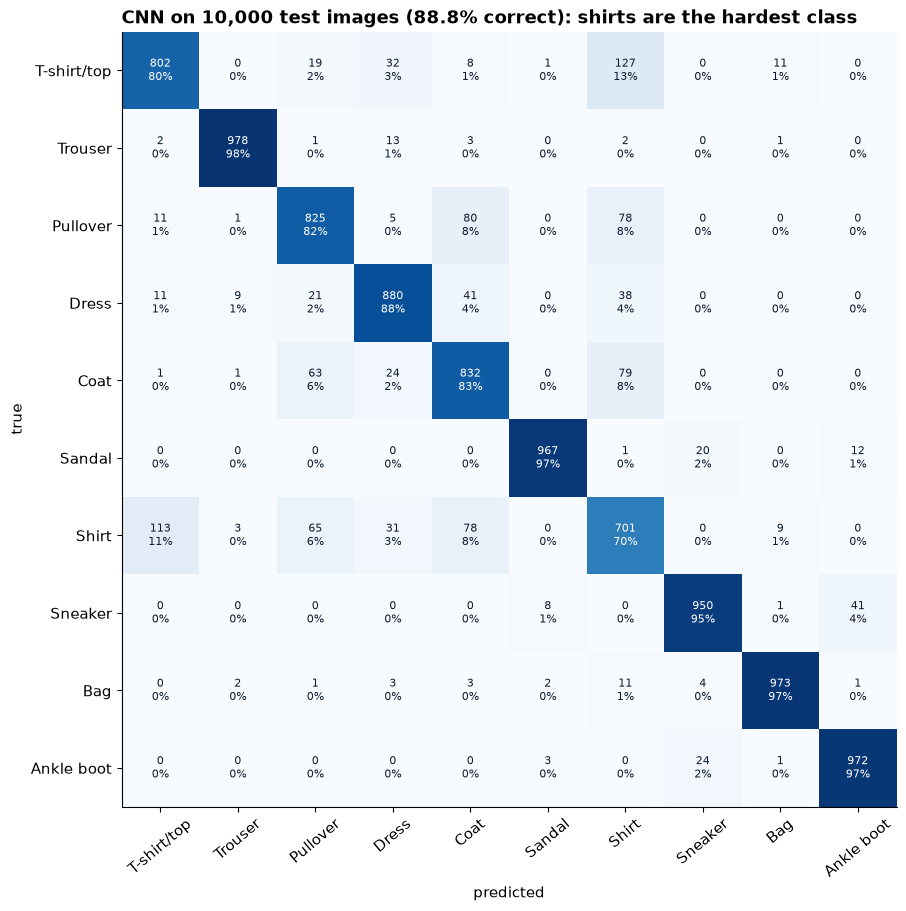

recall per class (worst first):
Shirt          0.701
T-shirt/top    0.802
Pullover       0.825
Coat           0.832
Dress          0.880
Sneaker        0.950
Sandal         0.967
Ankle boot     0.972
Bag            0.973
Trouser        0.978


In [17]:
fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
plot_confusion(test_cnn["confusion"], FASHION_CLASSES, ax=ax,
               title=f"CNN on 10,000 test images ({test_cnn['accuracy']:.1%} correct): shirts are the hardest class")
for t in ax.texts:
    t.set_fontsize(8)
ax.tick_params(axis="x", rotation=40)
plt.show()
per_class = pd.Series(test_cnn["confusion"].diagonal() / test_cnn["confusion"].sum(1), index=FASHION_CLASSES)
print("recall per class (worst first):"); print(per_class.sort_values().round(3).to_string())

### 🖼️ The most confident mistakes

Accuracy is a single number. Looking at **the errors the model was most sure about** tells you *why* it fails: a confusing label, a weird photo, or two classes that really overlap.

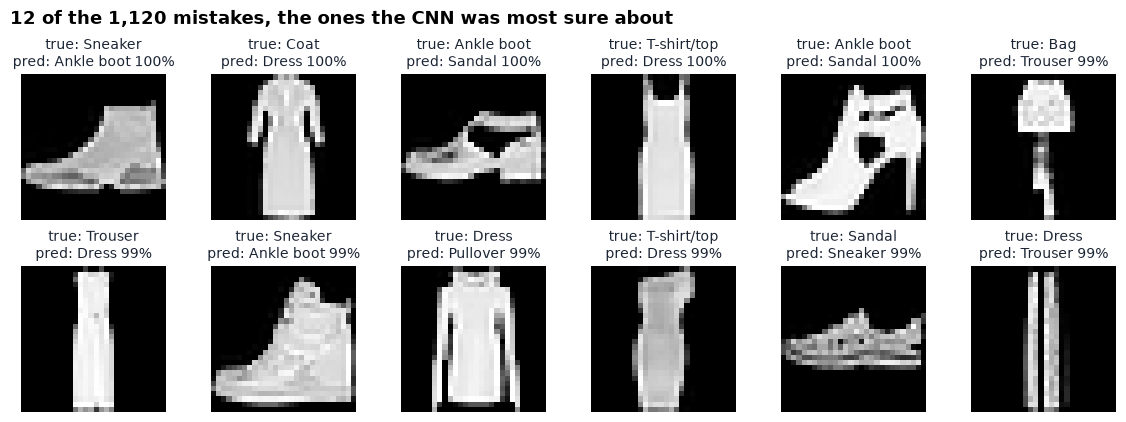

In [18]:
proba = test_cnn["proba"]                                     # (10000, 10), rows in the test-set order
wrong = np.flatnonzero(test_cnn["y_pred"] != test_cnn["y_true"])
worst = wrong[np.argsort(-proba[wrong].max(1))][:12]
titles = [f"true: {FASHION_CLASSES[test_cnn['y_true'][k]]}\npred: {FASHION_CLASSES[test_cnn['y_pred'][k]]} "
          f"{proba[k].max():.0%}" for k in worst]
fig = show_grid([X_test_u8[k] for k in worst], titles, ncols=6, size=1.9,
                suptitle=f"12 of the {len(wrong):,} mistakes, the ones the CNN was most sure about")
plt.show()

Many of these are debatable even for a human: a "shirt" that looks like a T-shirt, a "bag" photographed like a top, a sandal that could be a sneaker. At 28 × 28 pixels and grey only, some information is simply gone. Better models help, but **the data sets the ceiling**.

### 💬 Discussion — Is 90% good?

The CNN gets about 9 out of 10 test images right. Would you deploy it to tag the products of an online shop automatically? What would you do with the cases it is unsure about?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

Depends on the cost of an error. A wrong "shirt vs T-shirt" tag is cheap; a wrong "sandal vs ankle boot" might annoy customers. A common design: auto-tag when the top probability is above a threshold (e.g. 95%) and send the rest to a person — the threshold-tuning idea from Lesson 02. Also: real shop photos are colour, larger and varied; Fashion-MNIST is a clean benchmark. Notebook 04 moves to real photos.
</details>

<a id="sec-7"></a>
# 7. ✏️ Exercises

### ✏️ Exercise 1 — Design your own kernel

**Difficulty:** ⭐

Write a 3 × 3 kernel that detects **diagonal** edges (from top-left to bottom-right) and apply it to the ankle boot with `apply_kernel`. Show the original and the result side by side.

In [19]:
my_kernel = np.array([[0, 0, 0],
                      [0, 0, 0],
                      [0, 0, 0]], dtype=np.float32)   # TODO: change the 9 numbers
# TODO: out = apply_kernel(img01, my_kernel); show img01 and np.abs(out) side by side

<details>
<summary>💡 Show solution</summary>

Positive weights on one side of the diagonal and negative on the other; the sum is 0, so flat areas give 0.

```python
my_kernel = np.array([[ 0,  1, 2],
                      [-1,  0, 1],
                      [-2, -1, 0]], dtype=np.float32)
out = apply_kernel(img01, my_kernel)
show_grid([img01, np.abs(out)], ["original", "diagonal edges"], ncols=2, size=3, cmap="magma")
plt.show()
```
</details>

### ✏️ Exercise 2 — Which pair of classes is most confused?

**Difficulty:** ⭐⭐

From `res_cnn["confusion"]`, find the pair (true class, predicted class) with the most mistakes (ignore the diagonal). Show 8 validation images of that mistake.

In [20]:
cm = res_cnn["confusion"].copy()
# TODO: set the diagonal to 0, find the largest cell with np.unravel_index(cm.argmax(), cm.shape),
#       then select the validation images with that true and predicted class and call show_grid

<details>
<summary>💡 Show solution</summary>

It is usually **Shirt → T-shirt/top** (or the reverse), followed by Shirt ↔ Pullover/Coat.

```python
cm = res_cnn["confusion"].copy(); np.fill_diagonal(cm, 0)
t, p = np.unravel_index(cm.argmax(), cm.shape)
print(f"{cm[t, p]} images of {FASHION_CLASSES[t]} predicted as {FASHION_CLASSES[p]}")
sel = np.flatnonzero((res_cnn["y_true"] == t) & (res_cnn["y_pred"] == p))[:8]
show_grid([X_val_u8[k] for k in sel], ncols=8, size=1.5); plt.show()
```
</details>

### ✏️ Exercise 3 — A smaller MLP or a bigger CNN?

**Difficulty:** ⭐⭐

Train an MLP with only **32** hidden neurons (`784 → 32 → 10`) and a CNN with **32 and 64** kernels instead of 16 and 32. Compare parameters and validation accuracy with the models above (2 epochs each is enough to see the trend).

In [21]:
# TODO: small_mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 32), nn.ReLU(), nn.Linear(32, 10))
# TODO: train_model(small_mlp, train_dl, val_dl, epochs=2) and evaluate(...)

<details>
<summary>💡 Show solution</summary>

The 25k-parameter MLP loses a little accuracy (≈ 1–2 points); the wider CNN gains a little but costs more time. Parameters are not everything: *how* they are used (local, shared kernels) matters more.

```python
small_mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 32), nn.ReLU(), nn.Linear(32, 10))
wide_cnn = FashionCNN()
wide_cnn.features = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                  nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
wide_cnn.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.2), nn.Linear(64 * 7 * 7, 10))
for name, m in (("small MLP", small_mlp), ("wide CNN", wide_cnn)):
    set_seed(SEED); train_model(m, train_dl, val_dl, epochs=2, lr=2e-3, verbose=False)
    print(f"{name}: {count_parameters(m):,} params, accuracy {evaluate(m, val_dl)['accuracy']:.1%}")
```
</details>

### ✏️ Exercise 4 — Teach the MLP about shifts (data augmentation)

**Difficulty:** ⭐⭐⭐

The MLP failed on images moved 3 px. Train a new MLP where, in every batch, the images are randomly moved left or right by up to 3 px (use `torch.roll` on the last dimension, or `shift_right`). Does the validation accuracy on `shifted_dl` improve? What does it cost on the normal validation images?

In [22]:
def random_shift(x, max_px=3):
    # TODO: pick a random shift between -max_px and max_px and return torch.roll(x, shift, dims=-1)
    return x

# TODO: mlp_aug = ...; train_model(mlp_aug, train_dl, val_dl, epochs=EPOCHS, augment_fn=random_shift)

<details>
<summary>💡 Show solution</summary>

The shifted accuracy jumps back up (the MLP has now *seen* moved clothes) and the normal accuracy stays about the same. This is **data augmentation**: instead of changing the model, show it the variations you expect. Notebook 04 uses it on real photos. The CNN gets part of this robustness for free from its architecture.

```python
def random_shift(x, max_px=3):
    return torch.roll(x, int(torch.randint(-max_px, max_px + 1, (1,))), dims=-1)

set_seed(SEED)
mlp_aug = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))
train_model(mlp_aug, train_dl, val_dl, epochs=EPOCHS, lr=2e-3, augment_fn=random_shift, verbose=False)
print(f"normal {evaluate(mlp_aug, val_dl)['accuracy']:.1%} | moved 3 px {evaluate(mlp_aug, shifted_dl)['accuracy']:.1%}")
```
</details>

<a id="sec-8"></a>
# 8. 📌 Summary

In [23]:
print(f"Notebook run time: {(time.perf_counter() - T_START) / 60:.1f} min on this machine")

Notebook run time: 0.8 min on this machine


| Idea | In one line |
|---|---|
| **Pixels** | an image is a table of numbers (28 × 28 = 784 here; ×3 for colour) |
| **Flatten + MLP** | works (≈ 87%), but every pixel position is a separate input: a 3-px shift hurts a lot |
| **Kernel / convolution** | a 3 × 3 grid of weights slid over the image: multiply, sum, repeat → a feature map |
| **Pooling** | keep the strongest value of each 2 × 2 block: smaller maps, a little shift tolerance |
| **CNN** | learned kernels, shared across positions: better accuracy (≈ 89%) with ≈ 10× fewer parameters, more tolerant to shifts |
| **Evaluation** | confusion matrix + most-confident mistakes show *which* classes overlap (shirts!) |

**Checklist:** ☐ validation split from the training data, test used once at the end? ☐ evaluation loader with `shuffle=False`? ☐ images scaled to 0–1? ☐ parameters counted? ☐ mistakes looked at, not only the accuracy? ☐ a baseline (10% random, the MLP) to compare with?

<a id="sec-9"></a>
# 9. 📚 Learn more

- Xiao, Rasul & Vollgraf (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*. <https://arxiv.org/abs/1708.07747> · <https://github.com/zalandoresearch/fashion-mnist>
- Stanford CS231n, *Convolutional Neural Networks for Visual Recognition* (notes on convolution and pooling): <https://cs231n.github.io/convolutional-networks/>
- Interactive: *CNN Explainer* (Wang et al., 2020) — watch every kernel and feature map in the browser: <https://poloclub.github.io/cnn-explainer/>
- PyTorch tutorial, *Training a Classifier* (a small CNN on CIFAR-10): <https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html>
- Krizhevsky, Sutskever & Hinton (2012), *ImageNet Classification with Deep Convolutional Neural Networks* (AlexNet): <https://papers.nips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html>

---
<div align="center">

⬅️ [Previous: Challenge 1 · Flip It!](../../01_text_mining/03_challenge_flip_it/Challenge_1_Flip_It.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 04 · Cats vs dogs, and our pets](../02_project_cats_vs_dogs/04_Cats_vs_Dogs_And_Our_Pets.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>